In [226]:
%pip install -q pandas numpy seaborn matplotlib tensorflow keras imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


# Module 3.1 Assignment - ANN for Medical Diagnosis

> Submitted by Phillip Amir Esguerra

In [227]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from collections import Counter

## 1. Dataset Preparation

In [228]:
file = "enhanced_diabetes_dataset.csv"
df = pd.read_csv(file)

print("Data Frame shape: ", df.shape)

Data Frame shape:  (2000, 17)


In [229]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       2000 non-null   int64  
 1   Gender                    2000 non-null   int64  
 2   Pregnancies               2000 non-null   int64  
 3   Glucose                   2000 non-null   int64  
 4   BloodPressure             1902 non-null   float64
 5   SkinThickness             1914 non-null   float64
 6   Insulin                   2000 non-null   int64  
 7   BMI                       2000 non-null   float64
 8   DiabetesPedigreeFunction  2000 non-null   float64
 9   HbA1c                     2000 non-null   float64
 10  FastingBS                 2000 non-null   int64  
 11  Triglycerides             1909 non-null   float64
 12  HDL                       1904 non-null   float64
 13  Smoking                   2000 non-null   int64  
 14  Physical

In [230]:
df.head()

,Age,Gender,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,HbA1c,FastingBS,Triglycerides,HDL,Smoking,PhysicalActivity,Prediabetes,Diabetes
0,52,1,1,124,95.0,20.0,0,36.0,0.078,4.7,87,142.0,37.0,0,3.3,0,1
1,43,1,2,144,86.0,23.0,3,32.9,0.118,6.3,135,162.0,89.0,0,5.2,1,1
2,55,1,4,141,113.0,18.0,297,43.4,0.139,5.4,113,180.0,45.0,1,0.0,1,0
3,68,1,3,125,110.0,32.0,210,22.7,0.197,5.2,93,262.0,56.0,0,4.1,0,1
4,41,0,0,177,92.0,14.0,189,38.1,0.078,10.5,126,332.0,66.0,0,3.8,0,1


In [231]:
df.describe()

,Age,Gender,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,HbA1c,FastingBS,Triglycerides,HDL,Smoking,PhysicalActivity,Prediabetes,Diabetes
count,2000.000000,2000.000000,2000.000000,2000.000000,1902.000000,1914.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,1909.000000,1904.000000,2000.000000,1899.000000,2000.000000,2000.000000
mean,45.858500,0.614000,1.557000,127.156000,89.005258,22.551724,110.316500,29.493850,0.304637,6.179000,95.090000,196.518072,49.630777,0.222500,2.849236,0.422500,0.804000
std,14.155164,0.486952,1.758208,28.018051,12.119690,8.843040,114.417333,6.038741,0.289355,1.705257,22.969343,83.285277,16.232860,0.416029,2.756191,0.494081,0.397068
min,20.000000,0.000000,0.000000,70.000000,60.000000,5.000000,0.000000,16.000000,0.078000,4.000000,50.000000,50.000000,20.000000,0.000000,0.000000,0.000000,0.000000
25%,36.000000,0.000000,0.000000,107.000000,81.000000,16.000000,0.000000,25.400000,0.083750,4.700000,79.000000,137.000000,38.000000,0.000000,0.700000,0.000000,1.000000
50%,46.000000,1.000000,1.000000,126.000000,89.000000,22.000000,88.000000,29.550000,0.213000,6.000000,94.500000,195.000000,50.000000,0.000000,2.200000,0.000000,1.000000
75%,55.000000,1.000000,3.000000,146.000000,97.000000,28.000000,195.000000,33.600000,0.391250,7.400000,110.000000,256.000000,61.000000,0.000000,4.200000,1.000000,1.000000
max,80.000000,1.000000,10.000000,222.000000,130.000000,50.000000,548.000000,49.400000,2.500000,12.000000,171.000000,463.000000,100.000000,1.000000,20.000000,1.000000,1.000000


# 2. Data Cleanup and Preparation

> It says that this dataset contains health information for **female** patients. So I guess we should filter out males in the data set.

Gender Distribution:
0 = Male, 1 = Female
        Count  Percentage (%)
Gender                       
1        1228            61.4
0         772            38.6


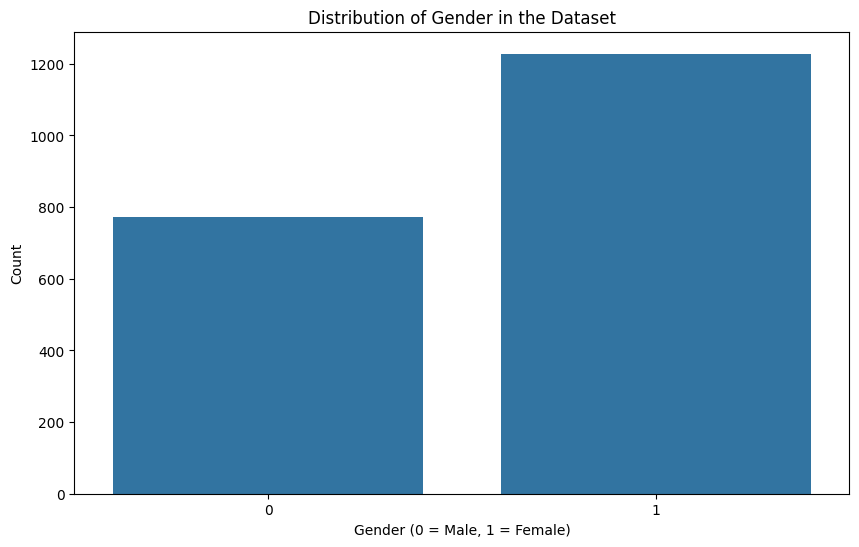


Percentage of female patients: 61.40%


In [232]:
# Check the distribution of gender in the dataset
gender_counts = df['Gender'].value_counts()
gender_percentage = df['Gender'].value_counts(normalize=True) * 100

# Create a dataframe to display the results
gender_distribution = pd.DataFrame({
    'Count': gender_counts,
    'Percentage (%)': gender_percentage
})

print("Gender Distribution:")
print("0 = Male, 1 = Female")
print(gender_distribution)

# Visualize gender distribution
plt.figure(figsize=(10, 6))
sns.countplot(x='Gender', data=df)
plt.title('Distribution of Gender in the Dataset')
plt.xlabel('Gender (0 = Male, 1 = Female)')
plt.ylabel('Count')
plt.show()

# Check if the dataset is primarily for female patients as mentioned
female_percentage = gender_percentage.get(1, 0)
print(f"\nPercentage of female patients: {female_percentage:.2f}%")

In [233]:
df_female = df[df['Gender'] == 1]

print(f"Original dataset shape: {df.shape}")
print(f"After filtering (females only): {df_female.shape}")
print(f"Removed {df.shape[0] - df_female.shape[0]} male records.")

df = df_female

df.head()

Original dataset shape: (2000, 17)
After filtering (females only): (1228, 17)
Removed 772 male records.


,Age,Gender,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,HbA1c,FastingBS,Triglycerides,HDL,Smoking,PhysicalActivity,Prediabetes,Diabetes
0,52,1,1,124,95.0,20.0,0,36.0,0.078,4.7,87,142.0,37.0,0,3.3,0,1
1,43,1,2,144,86.0,23.0,3,32.9,0.118,6.3,135,162.0,89.0,0,5.2,1,1
2,55,1,4,141,113.0,18.0,297,43.4,0.139,5.4,113,180.0,45.0,1,0.0,1,0
3,68,1,3,125,110.0,32.0,210,22.7,0.197,5.2,93,262.0,56.0,0,4.1,0,1
6,69,1,5,72,77.0,NaN,114,25.8,0.172,4.0,50,194.0,83.0,1,0.7,0,0


In [234]:
# Since all data is of female patients, we can drop the Gender column
df = df.drop('Gender', axis=1)
print(f"Column 'Gender' removed. New shape: {df.shape}")

df.head()

Column 'Gender' removed. New shape: (1228, 16)


,Age,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,HbA1c,FastingBS,Triglycerides,HDL,Smoking,PhysicalActivity,Prediabetes,Diabetes
0,52,1,124,95.0,20.0,0,36.0,0.078,4.7,87,142.0,37.0,0,3.3,0,1
1,43,2,144,86.0,23.0,3,32.9,0.118,6.3,135,162.0,89.0,0,5.2,1,1
2,55,4,141,113.0,18.0,297,43.4,0.139,5.4,113,180.0,45.0,1,0.0,1,0
3,68,3,125,110.0,32.0,210,22.7,0.197,5.2,93,262.0,56.0,0,4.1,0,1
6,69,5,72,77.0,NaN,114,25.8,0.172,4.0,50,194.0,83.0,1,0.7,0,0


In [235]:
# Check for missing values
missing_values = df.isnull().sum()
print("\nMissing values in each column:")
print(missing_values[missing_values > 0])



Missing values in each column:
BloodPressure       63
SkinThickness       59
Triglycerides       55
HDL                 60
PhysicalActivity    69
dtype: int64


In [236]:
df.dropna(inplace=True) 
df.shape

(945, 16)

## 2. Exploratory Data Analysis

### Correlation Matrix of Medical Data

In [237]:
correlation_matrix = df.corr()
correlation_matrix

,Age,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,HbA1c,FastingBS,Triglycerides,HDL,Smoking,PhysicalActivity,Prediabetes,Diabetes
Age,1.000000,0.032917,0.047842,0.354137,-0.172029,0.063022,0.126323,0.034420,0.011363,0.050565,0.138682,-0.037621,0.017981,-0.153536,0.010003,0.084073
Pregnancies,0.032917,1.000000,-0.036751,-0.055554,-0.025437,-0.011256,-0.019942,0.099937,-0.035247,-0.020931,0.026982,-0.036872,0.018556,0.015840,-0.020740,0.004950
Glucose,0.047842,-0.036751,1.000000,0.127278,0.009483,0.202673,0.296897,0.016388,0.706246,0.905805,0.114535,-0.036163,0.000150,0.022709,0.298992,0.274189
BloodPressure,0.354137,-0.055554,0.127278,1.000000,-0.082093,0.089191,0.319358,0.042655,0.070897,0.111987,0.131427,-0.028308,0.007325,-0.059303,0.002415,0.082899
SkinThickness,-0.172029,-0.025437,0.009483,-0.082093,1.000000,0.054454,-0.016365,0.073540,0.029881,-0.006255,-0.037697,0.104602,0.010321,0.040766,-0.025486,-0.027379
Insulin,0.063022,-0.011256,0.202673,0.089191,0.054454,1.000000,0.012735,0.051710,0.168662,0.186170,0.027358,-0.041795,0.017533,0.008986,0.017494,0.080214
BMI,0.126323,-0.019942,0.296897,0.319358,-0.016365,0.012735,1.000000,0.016703,0.216795,0.259362,0.264329,-0.168404,0.062550,-0.029398,0.069649,0.137090
DiabetesPedigreeFunction,0.034420,0.099937,0.016388,0.042655,0.073540,0.051710,0.016703,1.000000,-0.019217,0.006673,0.039067,-0.043191,0.027071,-0.019449,0.026892,0.105511
HbA1c,0.011363,-0.035247,0.706246,0.070897,0.029881,0.168662,0.216795,-0.019217,1.000000,0.645249,0.095536,-0.020242,0.010856,-0.006457,0.256813,0.337676
FastingBS,0.050565,-0.020931,0.905805,0.111987,-0.006255,0.186170,0.259362,0.006673,0.645249,1.000000,0.099145,-0.004737,0.015457,0.039340,0.345449,0.265569


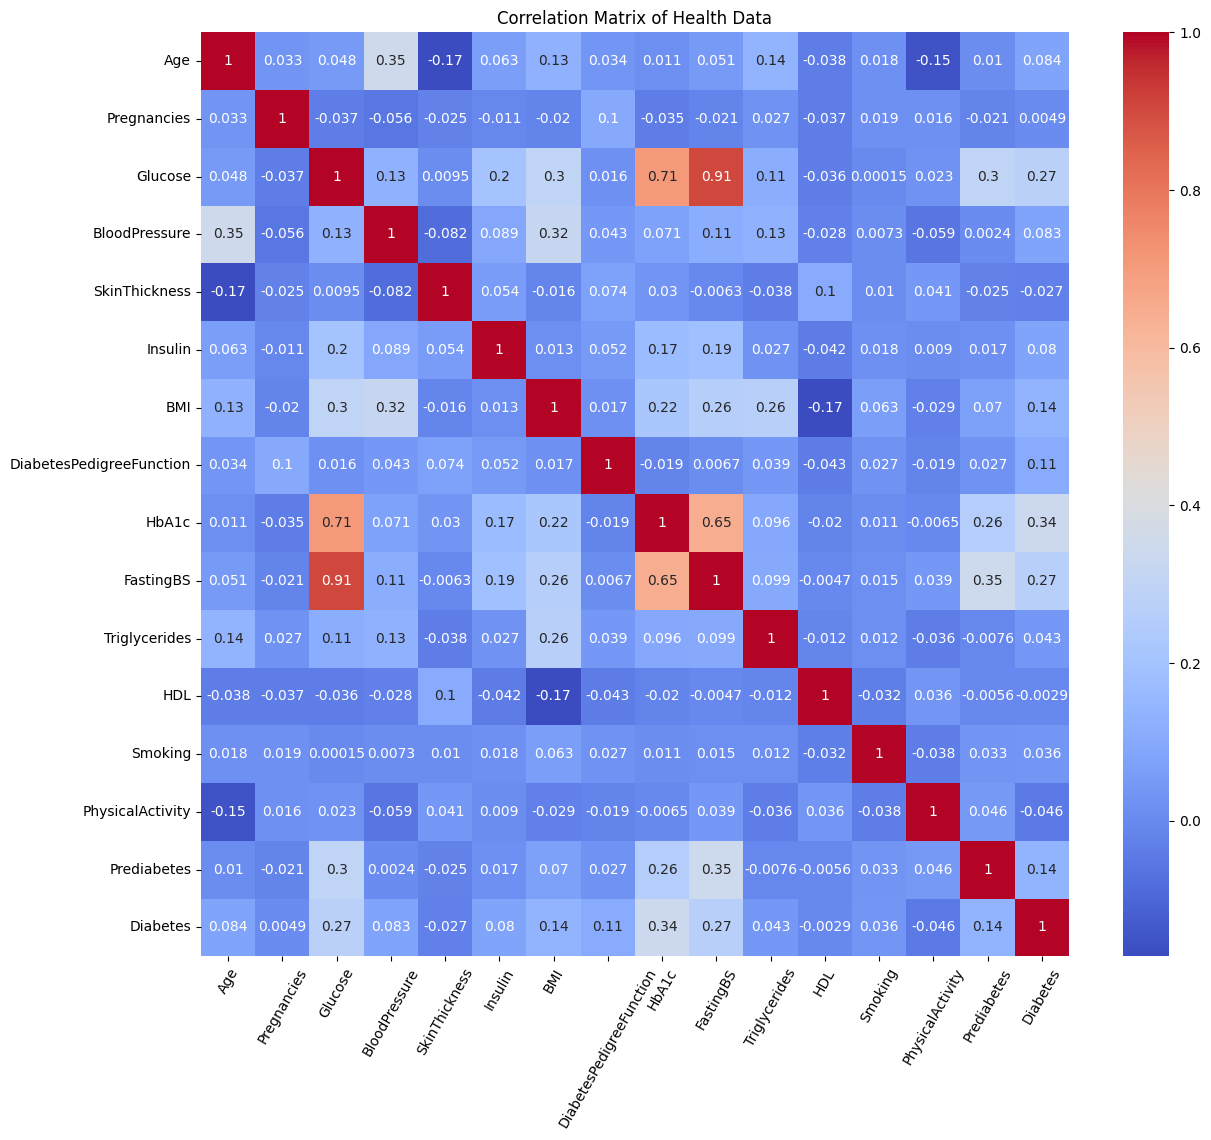

In [238]:
plt.figure(figsize=(14, 12))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix of Health Data")
plt.xticks(rotation=60)
plt.show()

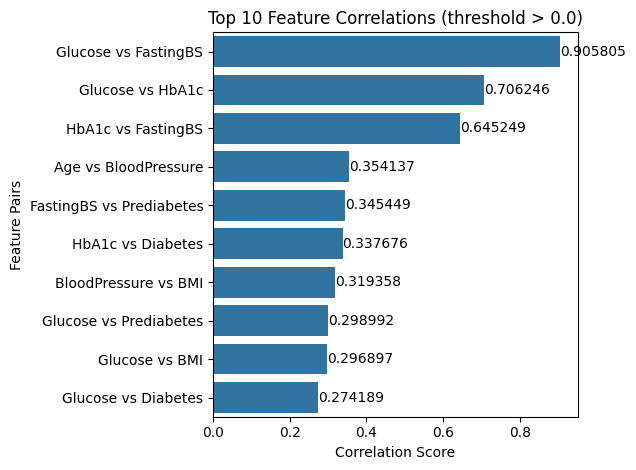

In [239]:
threshold = 0.0

# Extract correlation pairs greater than 0.1 (excluding self-correlations)
corr_pairs = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        corr_value = correlation_matrix.iloc[i, j]
        if abs(corr_value) > threshold:
            corr_pairs.append({
                'feature1': correlation_matrix.columns[i],
                'feature2': correlation_matrix.columns[j],
                'correlation': corr_value
            })

corr_df = pd.DataFrame(corr_pairs)
corr_df['abs_correlation'] = corr_df['correlation'].abs()
corr_df = corr_df.sort_values('abs_correlation', ascending=False)

plt.figure()
top_10 = corr_df.head(10)
ax = sns.barplot(x='correlation', y=top_10['feature1'] + ' vs ' + top_10['feature2'], data=top_10)
ax.bar_label(ax.containers[0], fontsize=10)
plt.title(f'Top 10 Feature Correlations (threshold > {threshold})')
plt.xlabel('Correlation Score')
plt.ylabel('Feature Pairs')
plt.tight_layout()
plt.show()

In [240]:
flat_var_list = [*top_10['feature1'], *top_10['feature2']]
flat_var_list = set(flat_var_list)

/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: in

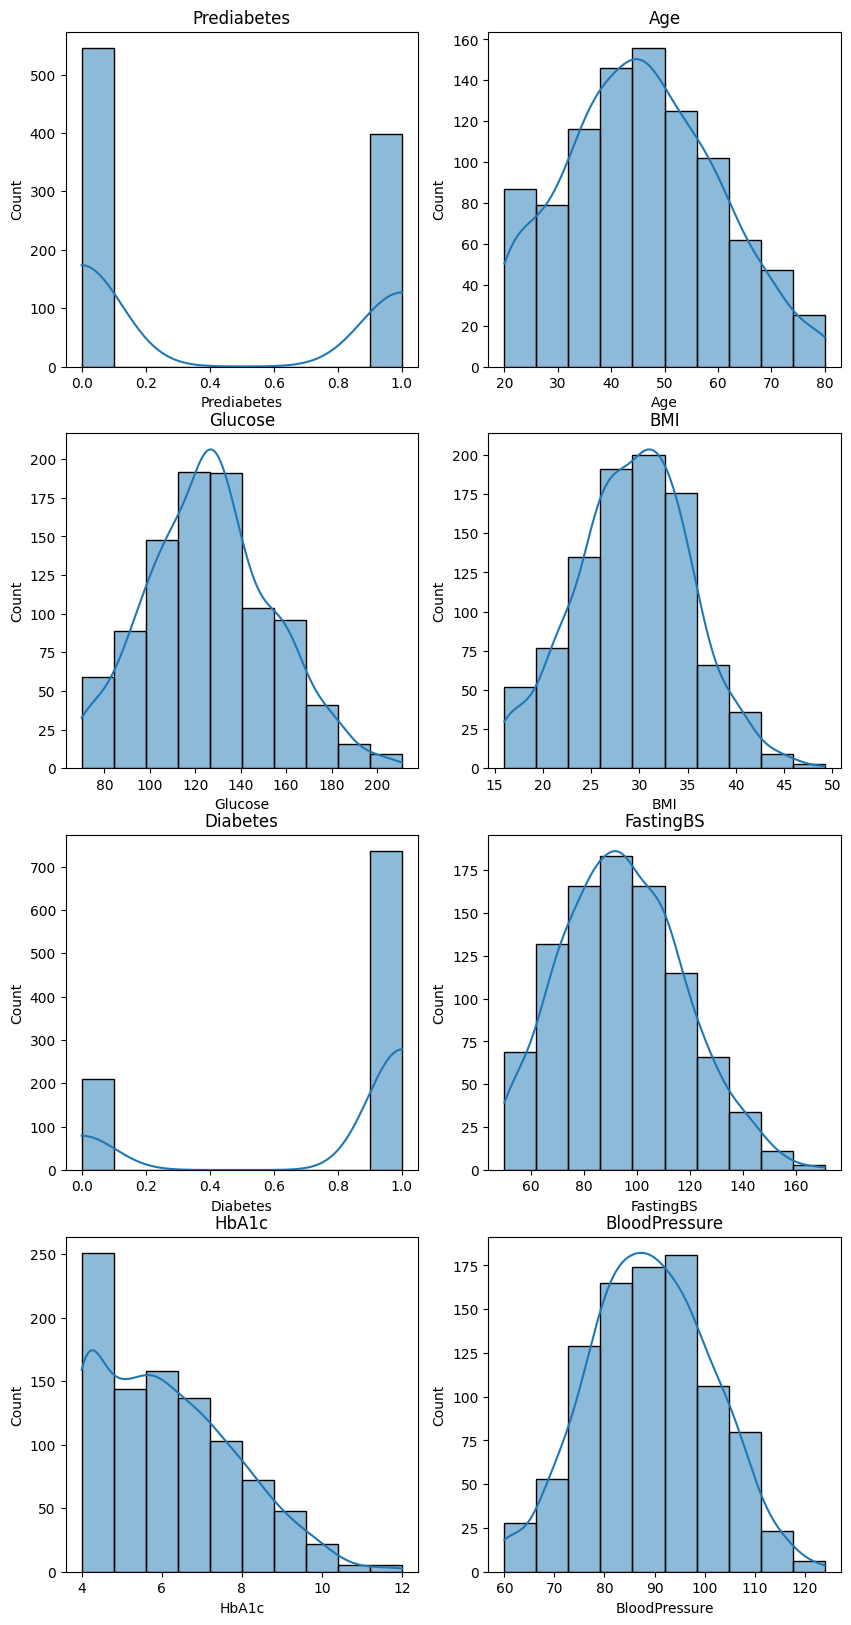

In [241]:
figure, axes = plt.subplots(4, 2, figsize=(10, 20))
axes = axes.flatten()

for i, var in enumerate(flat_var_list):
    sns.histplot(df[var], bins=10, kde=True, ax=axes[i])
    axes[i].set_title(var)

plt.show()

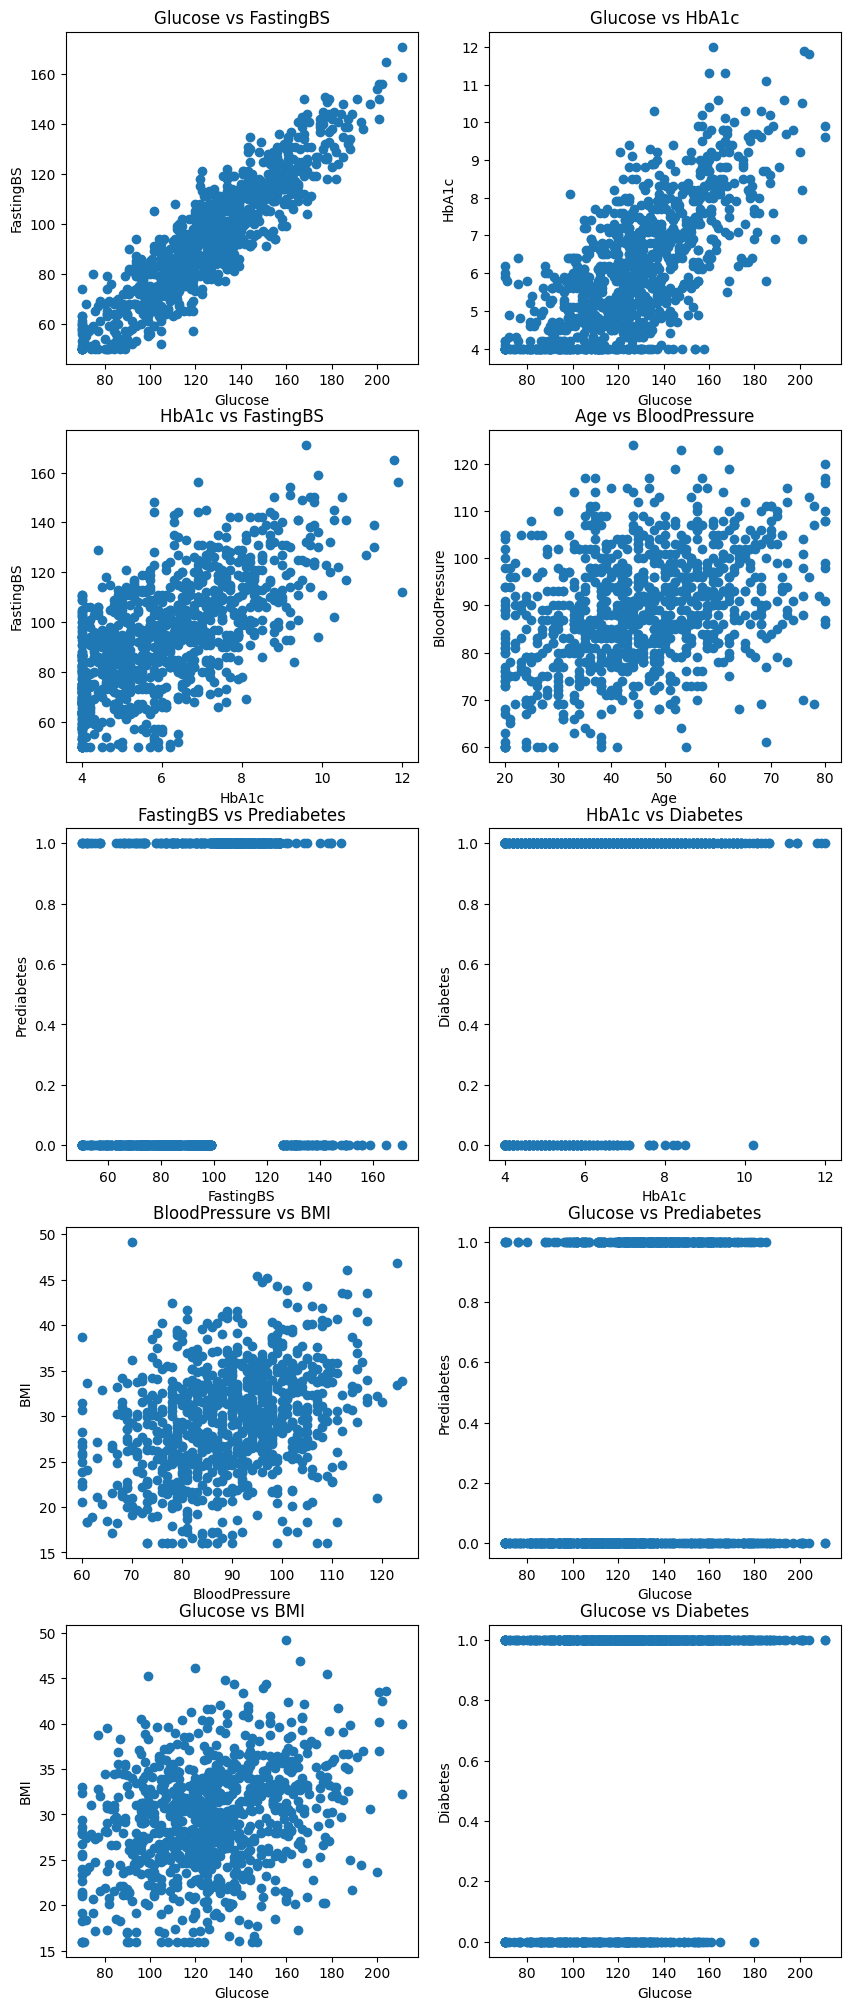

In [242]:
figure, axes = plt.subplots(5,2, figsize=(10, 25))
axes = axes.flatten()

# Create scatter plots for each pair
for i, (x_var, y_var) in enumerate(top_10[['feature1', 'feature2']].values):
    axes[i].set_title(f"{x_var} vs {y_var}")
    axes[i].scatter(df[x_var], df[y_var])
    axes[i].set_xlabel(x_var)
    axes[i].set_ylabel(y_var)

## 3. Further Data Cleanup

In [243]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Age                         0
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
HbA1c                       0
FastingBS                   0
Triglycerides               0
HDL                         0
Smoking                     0
PhysicalActivity            0
Prediabetes                 0
Diabetes                    0
dtype: int64


In [244]:
print("NaN values in each column:")
print(df.isna().sum())

NaN values in each column:
Age                         0
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
HbA1c                       0
FastingBS                   0
Triglycerides               0
HDL                         0
Smoking                     0
PhysicalActivity            0
Prediabetes                 0
Diabetes                    0
dtype: int64


### Checking for outliers

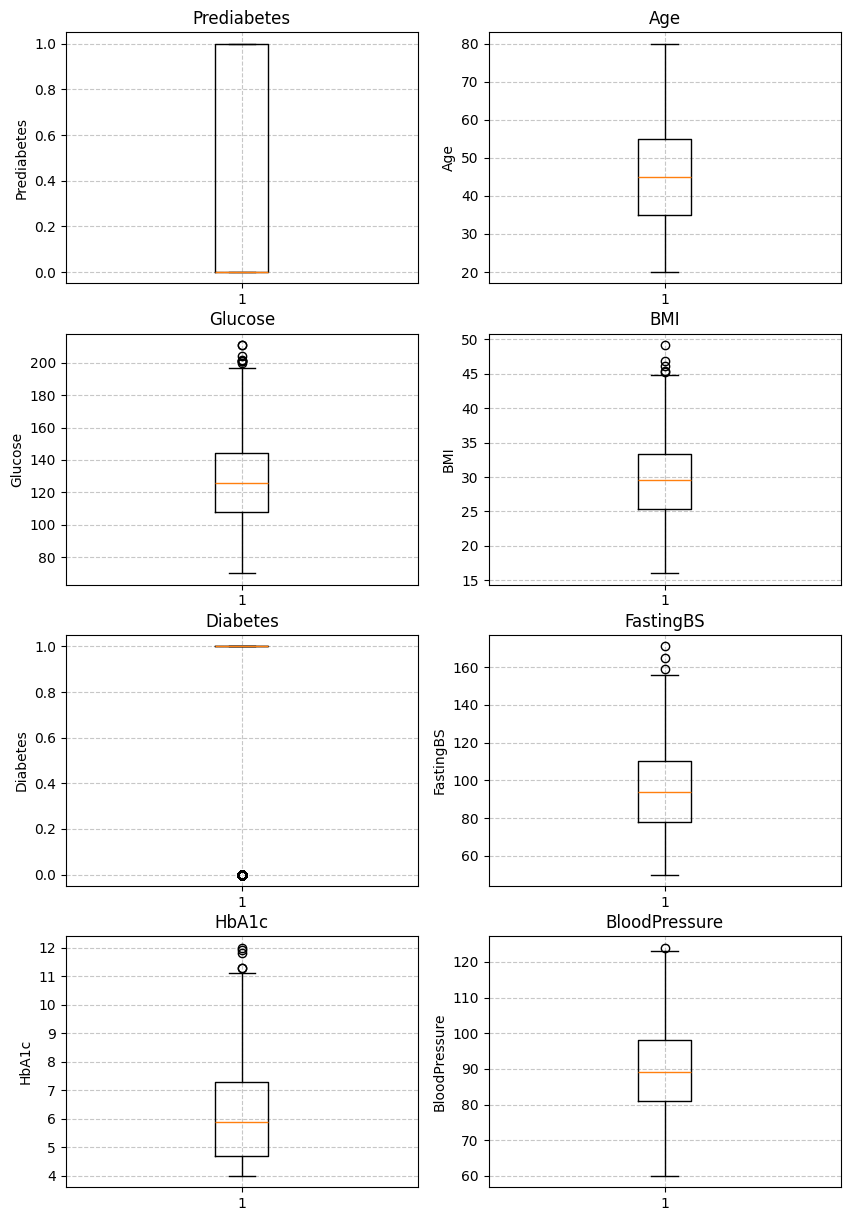

In [245]:
fig, axes = plt.subplots(4, 2, figsize=(10, 15))
axes = axes.flatten()

for i, var in enumerate(flat_var_list):
    axes[i].boxplot(df[var])
    axes[i].set_title(var)
    axes[i].set_ylabel(var)
    axes[i].grid(True, linestyle="--", alpha=0.7)

plt.show()

In [246]:
def get_outliers(data, var):
    df = data[var]
    q1 = np.percentile(df, 25)
    q3 = np.percentile(df, 75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = data[(df < lower_bound) | (df > upper_bound)]
    return outliers, lower_bound, upper_bound

columns = list(df.columns.values)

features_to_check = [f for f in columns if f != 'Diabetes']

for var in features_to_check:
    outliers, lower_bound, upper_bound = get_outliers(df, var)
    if not outliers.empty:
        print(f"Outliers in '{var}': {len(outliers)} outliers found")
        print(f"  - Range: values < {lower_bound:.2f} or > {upper_bound:.2f}")
        print(f"  - {len(outliers)} rows ({(len(outliers)/len(df)*100):.2f}% of data)")
    else:
        print(f"No outliers found in '{var}'.")

No outliers found in 'Age'.
Outliers in 'Pregnancies': 2 outliers found
  - Range: values < -3.50 or > 8.50
  - 2 rows (0.21% of data)
Outliers in 'Glucose': 8 outliers found
  - Range: values < 54.00 or > 198.00
  - 8 rows (0.85% of data)
Outliers in 'BloodPressure': 1 outliers found
  - Range: values < 55.50 or > 123.50
  - 1 rows (0.11% of data)
Outliers in 'SkinThickness': 4 outliers found
  - Range: values < 2.50 or > 46.50
  - 4 rows (0.42% of data)
No outliers found in 'Insulin'.
Outliers in 'BMI': 5 outliers found
  - Range: values < 13.55 or > 45.15
  - 5 rows (0.53% of data)
Outliers in 'DiabetesPedigreeFunction': 51 outliers found
  - Range: values < -0.39 or > 0.89
  - 51 rows (5.40% of data)
Outliers in 'HbA1c': 5 outliers found
  - Range: values < 0.80 or > 11.20
  - 5 rows (0.53% of data)
Outliers in 'FastingBS': 3 outliers found
  - Range: values < 30.00 or > 158.00
  - 3 rows (0.32% of data)
Outliers in 'Triglycerides': 2 outliers found
  - Range: values < -45.00 or > 

In [247]:
df_clean = df.copy()

for var in features_to_check:
    outliers, lower_bound, upper_bound = get_outliers(df, var)
    if not outliers.empty:
        col = df[var]
        df_clean = df[(col >= lower_bound) & (col <= upper_bound)]
    else:
        print(f"No outliers found in '{var}'.")

print("Shape of cleaned data:", df_clean.shape)

No outliers found in 'Age'.
No outliers found in 'Insulin'.
No outliers found in 'Prediabetes'.
Shape of cleaned data: (925, 16)


## 4-5. Feature Preparation

In [248]:
X = df.drop('Diabetes', axis=1)
y = df['Diabetes']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)



Feature shape: (945, 15)
Target shape: (945,)


In [249]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=0)

In [250]:
print("Training set shape:", X_train.shape, y_train.shape)
print("Temp set shape:", X_temp.shape, y_temp.shape)

Training set shape: (756, 15) (756,)
Temp set shape: (189, 15) (189,)


In [251]:
sm = SMOTE(random_state=420)
X_res, y_res = sm.fit_resample(X, y)

print(f"Resampled dataset shape: {Counter(X_res)}")
print(f"Resampled dataset shape: {Counter(y_res)}")

Resampled dataset shape: Counter({'Age': 1, 'Pregnancies': 1, 'Glucose': 1, 'BloodPressure': 1, 'SkinThickness': 1, 'Insulin': 1, 'BMI': 1, 'DiabetesPedigreeFunction': 1, 'HbA1c': 1, 'FastingBS': 1, 'Triglycerides': 1, 'HDL': 1, 'Smoking': 1, 'PhysicalActivity': 1, 'Prediabetes': 1})
Resampled dataset shape: Counter({1: 736, 0: 736})


In [252]:
X_res.reset_index(drop=True, inplace=True)
y_res.reset_index(drop=True, inplace=True)

X_train, X_temp, y_train, y_temp = train_test_split(
    X_res, y_res, test_size=0.30, random_state=420, stratify=y_res
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=420, stratify=y_temp
)

print(f"Training set shape: X_train={X_train.shape}, y_train={y_train.shape} ({Counter(y_train)})")
print(f"Validation set shape: X_val={X_val.shape}, y_val={y_val.shape} ({Counter(y_val)})")
print(f"Test set shape: X_test={X_test.shape}, y_test={y_test.shape} ({Counter(y_test)})")

Training set shape: X_train=(1030, 15), y_train=(1030,) (Counter({1: 515, 0: 515}))
Validation set shape: X_val=(221, 15), y_val=(221,) (Counter({0: 111, 1: 110}))
Test set shape: X_test=(221, 15), y_test=(221,) (Counter({1: 111, 0: 110}))


In [253]:
from sklearn.preprocessing import StandardScaler

scaler_X = StandardScaler()
# scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_val_scaled = scaler_X.transform(X_val)
X_test_scaled = scaler_X.transform(X_test)

# y_train_scaled = scaler_y.fit_transform(y_train.to_numpy().reshape(-1, 1))
# y_val_scaled = scaler_y.transform(y_val.to_numpy().reshape(-1, 1))
# y_test_scaled = scaler_y.transform(y_test.to_numpy().reshape(-1, 1))

In [254]:
print(f"Training set shape: X_train={X_train.shape}, y_train={y_train.shape} ({Counter(y_train)})")
print(f"Validation set shape: X_val={X_val.shape}, y_val={y_val.shape} ({Counter(y_val)})")
print(f"Test set shape: X_test={X_test.shape}, y_test={y_test.shape} ({Counter(y_test)})")

Training set shape: X_train=(1030, 15), y_train=(1030,) (Counter({1: 515, 0: 515}))
Validation set shape: X_val=(221, 15), y_val=(221,) (Counter({0: 111, 1: 110}))
Test set shape: X_test=(221, 15), y_test=(221,) (Counter({1: 111, 0: 110}))


In [255]:
# Reassigning the scaled variables to the original variable names
X_train = X_train_scaled
X_val = X_val_scaled
X_test = X_test_scaled
# y_train = y_train_scaled
# y_val = y_val_scaled
# y_test = y_test_scaled

## 6. DCNN Model

In [256]:
num_features = X_train.shape[1]
print(f"Input feature count: {num_features}")

Input feature count: 15


In [257]:
from tensorflow.keras.layers import Dense , Dropout, Conv1D, MaxPooling1D, Flatten
from tensorflow.keras.regularizers import l2
from tensorflow.keras.models import Sequential

model = Sequential()
model.add(Conv1D(16, 3, activation="relu", input_shape=(num_features,1)))
model.add(Dense(32, input_dim=num_features, activation="relu", kernel_regularizer=l2(0.001)))
model.add(Dense(16, activation="relu", kernel_regularizer=l2(0.001)))
model.add(MaxPooling1D())
model.add(Flatten())
model.add(Dense(32, activation="relu", kernel_regularizer=l2(0.001)))
model.add(Dropout(0.1))
model.add(Dense(16, kernel_initializer="normal", activation="relu", kernel_regularizer=l2(0.001)))
model.add(Dense(16, kernel_initializer="normal", activation="relu"))
model.add(Dropout(0.2))
model.add(Dense(1, activation="sigmoid"))

# keras.utils.plot_model(model, show_shapes=True)

/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


> Setting the output of the first layer to 32 doesn't work really well, so we tired to double it and it works great.
> 

In [258]:
from tensorflow.keras.optimizers import Adam

optimizer = Adam(learning_rate=0.001)
model.compile(loss="binary_crossentropy", optimizer=optimizer, metrics=["accuracy"])

> Optimizer: 'adam' was used as it is the widely used optimizer.
> 
> Loss: 'binary_crossentropy' is used for binary classification
> 
> Metrics: 'accuracy' is most common for classification

# 7-11. Model Training and Hyperparameter Tuning

Epoch 1/800


65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5753 - loss: 0.7697 - val_accuracy: 0.7195 - val_loss: 0.6945
Epoch 2/800
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 896us/step - accuracy: 0.6779 - loss: 0.6767 - val_accuracy: 0.7511 - val_loss: 0.5888
Epoch 3/800
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 791us/step - accuracy: 0.7386 - loss: 0.6013 - val_accuracy: 0.7738 - val_loss: 0.5603
Epoch 4/800
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 792us/step - accuracy: 0.7244 - loss: 0.5897 - val_accuracy: 0.7919 - val_loss: 0.5395
Epoch 5/800
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 776us/step - accuracy: 0.7181 - loss: 0.5957 - val_accuracy: 0.7466 - val_loss: 0.5543
Epoch 6/800
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 793us/step - accuracy: 0.7113 - loss: 0.6005 - val_accuracy: 0.7511 - val_loss: 0.5493
Epoch 7/800
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 781us/step - accuracy: 0.7404 - loss: 0.5585 - val_accuracy: 0.7783 - val_loss: 0.5267
Epoch 8/800
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 764us/step - accuracy: 0.7348 - loss: 0.5689 - val_accuracy: 0.7783 -

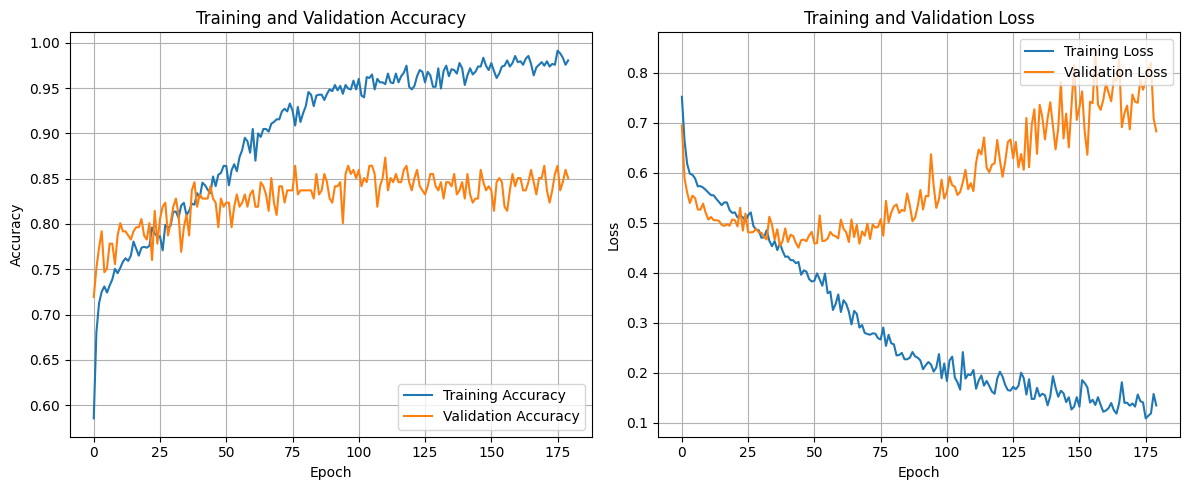

In [259]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(monitor='val_accuracy', 
                               patience=69, 
                               restore_best_weights=True, 
                               verbose=1)

history = model.fit(X_train, y_train, 
                    epochs=800, batch_size=16, 
                    validation_data=(X_val, y_val), 
                    callbacks=[early_stopping], verbose=1)

acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label="Training Accuracy")
plt.plot(epochs_range, val_acc, label="Validation Accuracy")
plt.legend(loc="lower right")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
# plt.xscale("log")
plt.ylabel("Accuracy")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Training Loss")
plt.plot(epochs_range, val_loss, label="Validation Loss")
plt.legend(loc="upper right")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
# plt.xscale("log")
plt.ylabel("Loss")
plt.grid(True)

plt.tight_layout()
plt.show()

> Initially trained on 800 epochs but seeing massive sudden drop in accuracy and sudden spike validation loss. Which can be indicative of overfitting.
> 
> EarlyStopping callback was also added so that it stops once the validation accuracy consistently gets better.
>
> Experimented with kernel_regularization, and while 0.01 is the usual value, setting 0.001 shows better convergence in the graph.
> 
> Experimented around Adam's learning rate, and 0.0001 seems a good value with smooth convergence

In [260]:
epochs_range = len(acc)
print("Ideal epochs range:", epochs_range)

Ideal epochs range: 180


# 12. Evaluation

In [261]:
# X_test.reset_index(drop=True, inplace=True)
# y_test.reset_index(drop=True, inplace=True)
X_test = pd.DataFrame(X_test)
y_test = pd.DataFrame(y_test).reset_index(drop=True)

print(X_test.shape)
print(y_test.shape)

prediction = model.predict(X_test)
prediction = [round(x[0]) for x in prediction] # round predictions to 0 or 1

for i in range(25):
	print('%d (expected %d)' % (prediction[i], y_test.iloc[i]))

(221, 15)
(221, 1)
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
0 (expected 0)
0 (expected 0)
0 (expected 0)
0 (expected 0)
1 (expected 1)
0 (expected 1)
0 (expected 0)
0 (expected 0)
0 (expected 0)
1 (expected 1)
1 (expected 0)
1 (expected 1)
1 (expected 1)
1 (expected 1)
0 (expected 0)
0 (expected 0)
1 (expected 1)
0 (expected 0)
1 (expected 1)
0 (expected 1)
0 (expected 0)
0 (expected 0)
1 (expected 1)
1 (expected 1)
0 (expected 0)


/var/folders/5t/yhw_yxtj4hd3cl86y215nn0h0000gn/T/ipykernel_67068/2090621067.py:13: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  print('%d (expected %d)' % (prediction[i], y_test.iloc[i]))


In [262]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, prediction)
precision = precision_score(y_test, prediction)
recall = recall_score(y_test, prediction)
f1 = f1_score(y_test, prediction)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

Accuracy: 0.8326
Precision: 0.8627
Recall: 0.7928
F1-Score: 0.8263


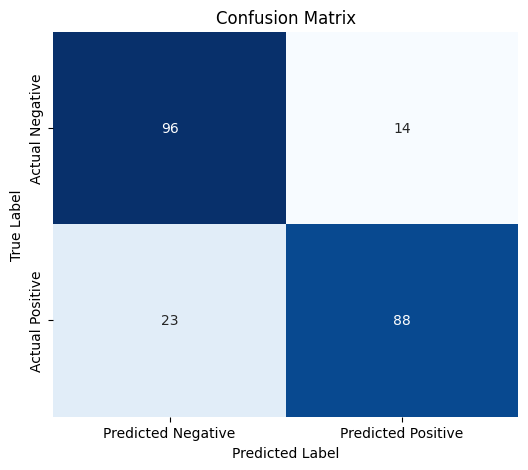

In [263]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm = confusion_matrix(y_test, prediction)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Negative', 'Predicted Positive'],
            yticklabels=['Actual Negative', 'Actual Positive'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

> We got a couple of false positives at 323 and false negatives at 16

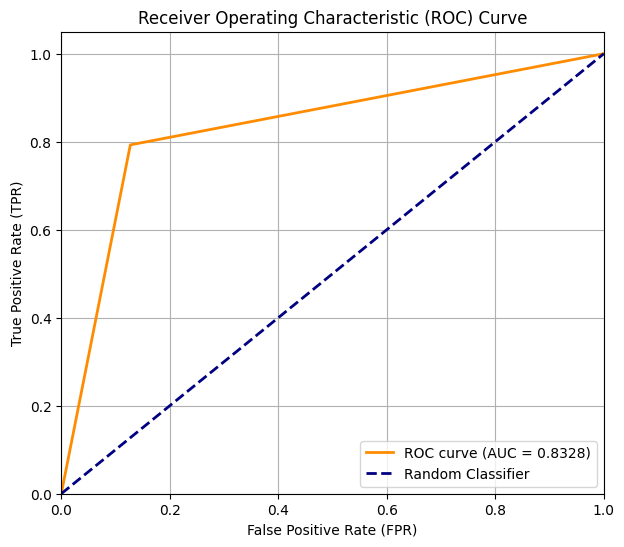

In [264]:
from sklearn.metrics import (
    roc_curve,
    auc
)

fpr, tpr, thresholds = roc_curve(y_test, prediction)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()